In [ ]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
pistack_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import grouped_boxplot_ax, box_plot_data
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import plot

os.chdir(pistack_dir)
df = pd.read_csv('pi_stack_EDA.csv', index_col=0)
# df = raw_df.query('TOTAL < 0')
df.shape

(924, 40)

In [5]:
print(len(df.query('TOTAL > 0'))) 
print(len(df.query('TOTAL < 0')))

10
914


In [6]:
labels = ['Parallel', 'T-Shaped']

def split_type(df):
    dfList = []
    dfList.append(df.query('type == "P" & TOTAL < 0'))
    dfList.append(df.query('type == "T" & TOTAL < 0'))
    return dfList

In [7]:
plot?

Signature:
plot(
    type,
    args,
    dfs,
    ax,
    cmap_range=[-100, 0.0],
    median=False,
    ratio1=False,
    ratio2=False,
    plot=False,
    kde_norm=False,
)
Docstring:
General Plot Function

Parameters
----------
type: {'ternary', 'bar', 'dist', 'box'}
    Plot types
args: list
    List of arguments for each plot type:
    - 'ternary': (label, index, type, cmap_range)
        - label: str
            type of atom/interaction
        - index: str
            index for ternary plot
        - type: str
            type of ternary plot ('frz_orb_disp', 'elec_orb_disp', 'frz_pol_ct')
    - 'bar': (labels, items)
        - label: list(str)
            type of atom/interaction
        - items: list(str)
            EDA energy components 
    - 'dist': (column, labels, item, palette)
        - column: str
            column of dataframe
        - label: list(str)
            type of atom/interaction
        - item: list(str)
            EDA energy components
        - palette:

# Parallel T-Shaped Comparison

# Ternary Plots

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_44069/668042241.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


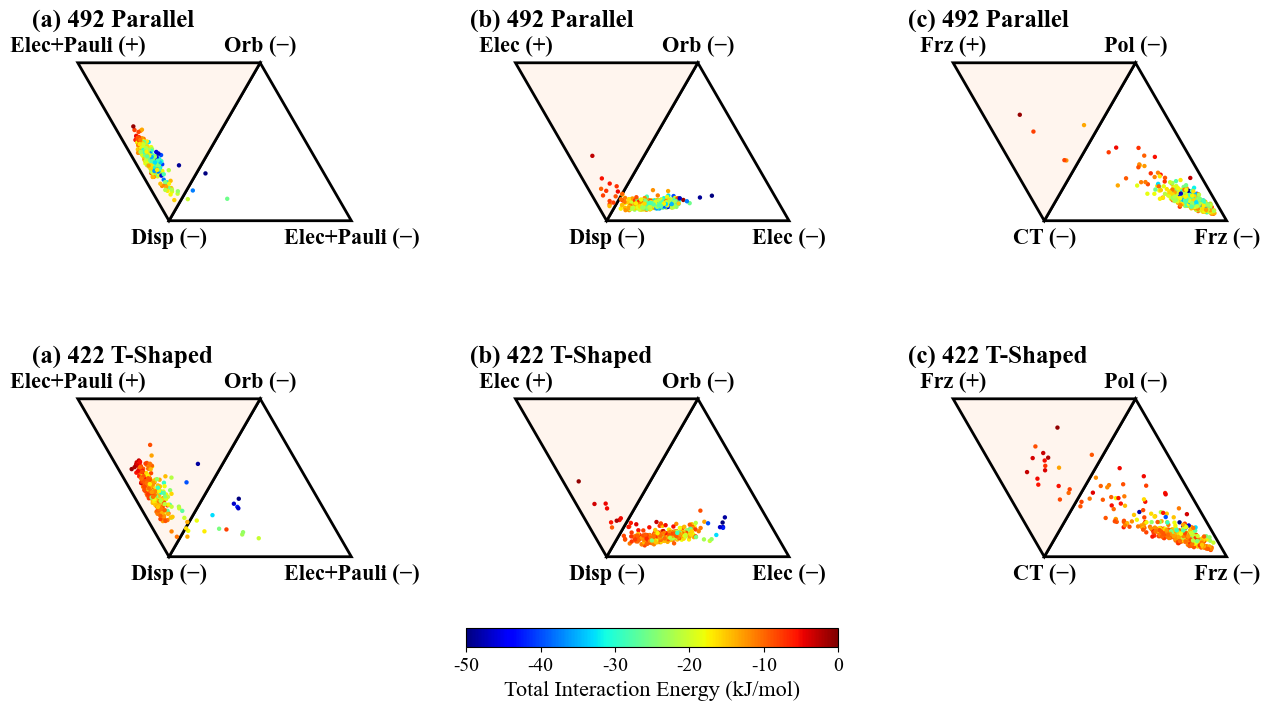

In [8]:
dfs = split_type(df)
cmap_range = [-50, 0]
type0 = 'frz_orb_disp'
type1 = 'elec_orb_disp'
type2 = 'frz_pol_ct'


fig, axes = plt.subplots(2, 3, figsize=(16, 10))
sc = plot('ternary', (labels[0], 'a', type0), dfs[0], axes[0, 0], cmap_range)
plot('ternary', (labels[0], 'b', type1), dfs[0], axes[0, 1], cmap_range)
plot('ternary', (labels[0], 'c', type2), dfs[0], axes[0, 2], cmap_range)
plot('ternary', (labels[1], 'a', type0), dfs[1], axes[1, 0], cmap_range)
plot('ternary', (labels[1], 'b', type1), dfs[1], axes[1, 1], cmap_range)
plot('ternary', (labels[1], 'c', type2), dfs[1], axes[1, 2], cmap_range)


cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

plt.savefig('Visualizations/ternary_T-P.png')


# Energy Bar Plots

## Bar Plot Ratio type formulation

### ratio1: $R_1 = \frac{\sum_{i} E_{i}^{(t)}}{\sum_{i} E_{i}^{(\text{total})}}$

### ratio2: $R_2 = \sum_{i} \frac{E_{i}^{(t)}}{E_{i}^{(\text{total})}}$

len: list(map(len, dfs))
len: list(map(len, dfs))


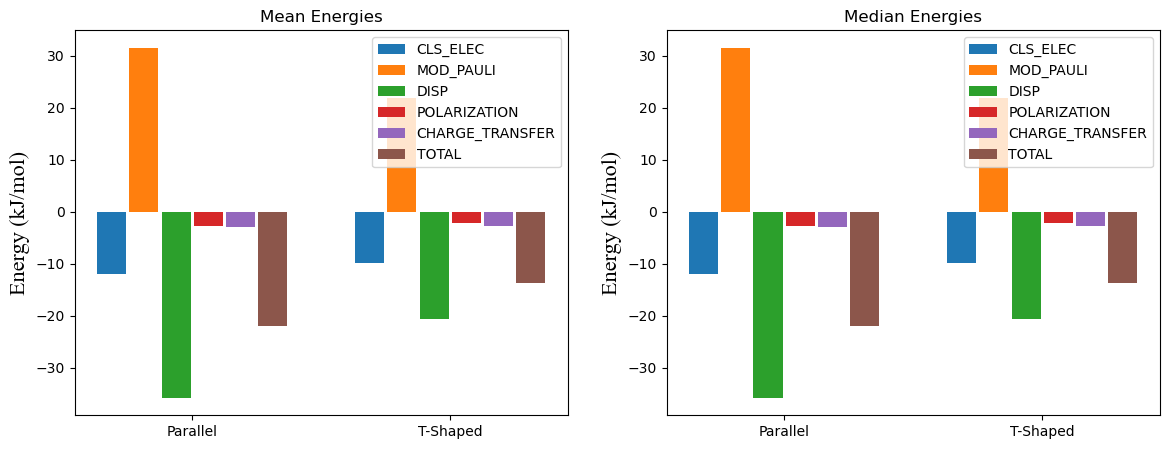

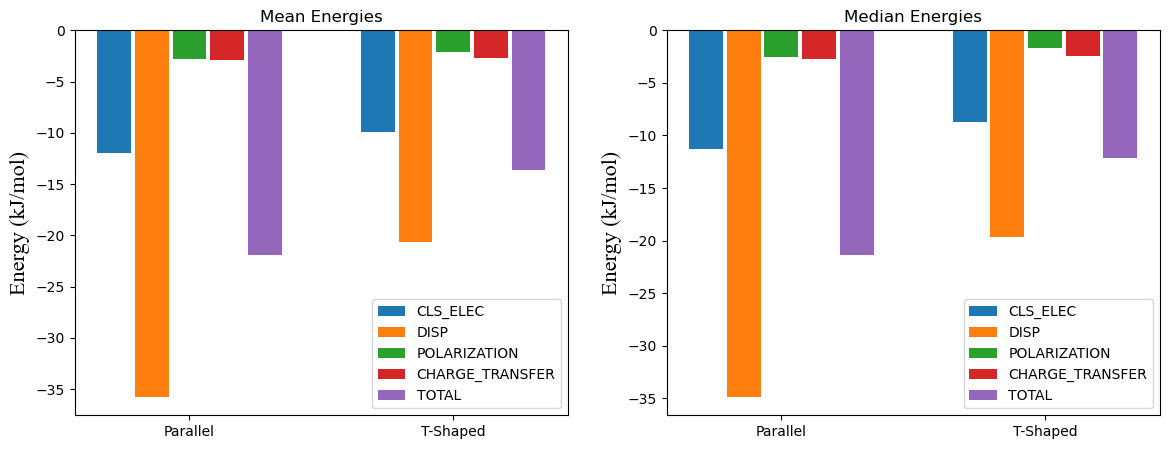

In [9]:
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]
dfs = split_type(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=False)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_all_T-P.png')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]
dfs = split_type(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_T-P.png')

# Heteroatom vs Pure Aromatic comparison

## Protein Fragment Visualization + Processing

318
606


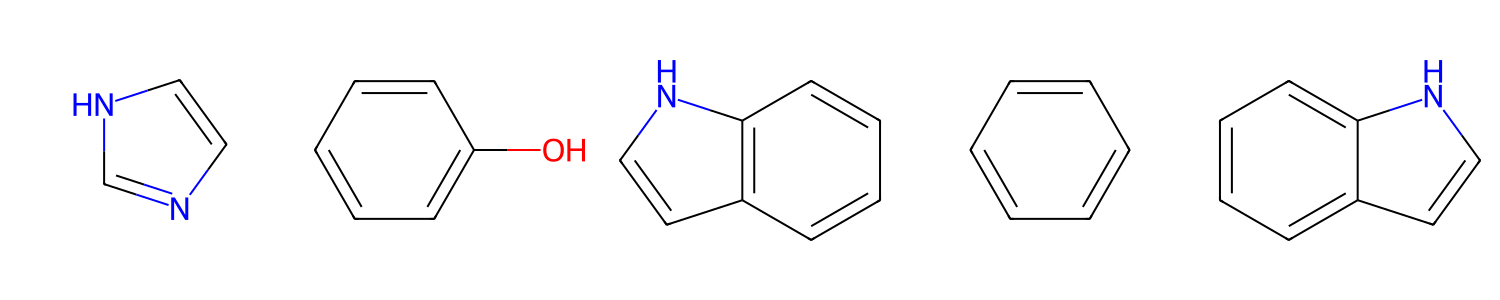

In [10]:
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

hetratom_prot = []
aromatic_prot = []

for index, row in df.iterrows():
    if row['restype'] == 'TYR' or row['restype'] == 'PHE':
        aromatic_prot.append(index)
    else:
        hetratom_prot.append(index)

print(len(hetratom_prot))
print(len(aromatic_prot))

Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df['smiles1'])], subImgSize=(300, 300), molsPerRow=5)


## Ligand Fragment Visualization + Processing

In [11]:
# manually checking lignad types
# Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in df['smiles0'][:500]], legends=[f"{id1}\n{id2}" for id1, id2 in zip(df['PDBID'][:500], df['smiles0'][:500])], subImgSize=(300, 300), molsPerRow=7, maxMols=500)
# Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in df['smiles0'][500:]], legends=[id for id in df['PDBID'][500:]], subImgSize=(300, 300), molsPerRow=7, maxMols=500)

In [12]:
from edautils.fragment import find_rings

dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
hetratom_lig = []
aromatic_lig = []

hetrato_atoms = []
aromatic_atoms = []

errs = []

for index, row in df.iterrows():
    aromatic = True
    temp_atomlist = []
    ligand = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf")
    mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
    ring_list = find_rings(mol, find_hetero_rings=False, find_small_rings=False) # only aromatic rings, idx numbers in OpenBabel 1 lower than Plip

    lig_idx_list = row['lig_idx_list'].split()
    lig_idx_set = set([int(id) - 1 for id in lig_idx_list])
    ring_temp = [s for s in ring_list if lig_idx_set & s]
    
    if row['PDBID'] == '3b2q': # Plip ring missidentification
        ring_temp = [21, 22, 23, 24, 25, 27, 28, 29, 30]
    elif row['PDBID'] == '2cm8': # reassign to aromatic ring
        ring_temp = [8, 9, 10, 11, 12, 13] 

    try:
        for idx in ring_temp[0]:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
            if not symbol == 'C':
                aromatic = False

        if aromatic:
            aromatic_lig.append(index)
            aromatic_atoms.append((index, temp_atomlist)) # keep the list of atoms
        else:
            hetratom_lig.append(index)
            hetrato_atoms.append((index, temp_atomlist)) # keep the list of atoms
    except Exception as e:
        for idx in lig_idx_set:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
        errs.append([index, temp_atomlist])

print(len(aromatic_lig))
print(len(hetratom_lig))

errPDBID = [err[0] for err in errs]
errs

413
502


[['3wtm_186_TYR_2926-2935_7-14', ['N', 'C', 'N', 'C', 'C']],
 ['5oh7_166_TRP_2563-2573_2-6', ['C', 'C', 'N', 'N', 'C']],
 ['4bj8_212_TRP_3179-3192_11-16', ['C', 'N', 'C', 'N', 'C']],
 ['2ovh_99_PHE_1649-1658_11-17', ['C', 'C', 'C', 'C', 'C', 'C']],
 ['5oha_69_TRP_1065-1071_2-6', ['C', 'C', 'N', 'C', 'N']],
 ['2bgd_183_PHE_3049-3058_2-8', ['C', 'N', 'S', 'N', 'C']],
 ['3wth_55_TRP_896-906_9-13', ['N', 'C', 'C', 'N', 'C']],
 ['4dve_161_PHE_2469-2478_11-16', ['C', 'N', 'C', 'N', 'C']],
 ['2nta_182_PHE_3025-3034_8-17', ['N', 'N', 'C', 'C', 'S']]]

In [13]:
labels = ['Heteroatom', 'Aromatic', 'Hetero-Aromatic']

def split_hetr_aromatic(df, errPDBID):
    df0 = pd.DataFrame()
    df1 = pd.DataFrame()
    df2 = pd.DataFrame()

    for index, row in df.iterrows():
        if index in errPDBID:
            continue
        elif index in hetratom_prot and index in hetratom_lig:
            df0 = pd.concat([df0, row.to_frame().T])
        elif index in aromatic_lig and index in aromatic_lig:
            df1 = pd.concat([df1, row.to_frame().T])
        else:
            df2 = pd.concat([df2, row.to_frame().T])
    return [df0, df1, df2]

df_whole = split_hetr_aromatic(df,errPDBID)
df_P = split_hetr_aromatic(dfs[0], errPDBID)
df_T = split_hetr_aromatic(dfs[1], errPDBID)

In [14]:
# print(dfs[0].shape)
# print(dfs[1].shape)
# print('\n')

# for df in df_whole:
#     print(df.shape)
# print('\n')

# for df in df_P:
#     print(df.shape)
# print('\n')

# for df in df_T:
#     print(df.shape)
# print('\n')

# Heteroatom vs Pure Aromatic Ternary

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_44069/2187655575.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


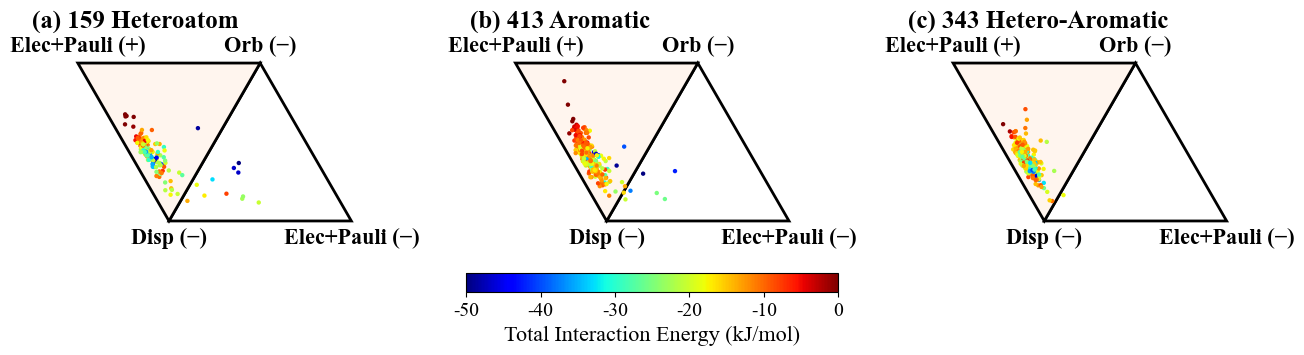

In [15]:
cmap_range = [-50, 0]
type = 'frz_orb_disp'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), df_whole[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), df_whole[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), df_whole[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

plt.savefig('ternary_hetratm-aromatic_1.png')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_44069/3454050372.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


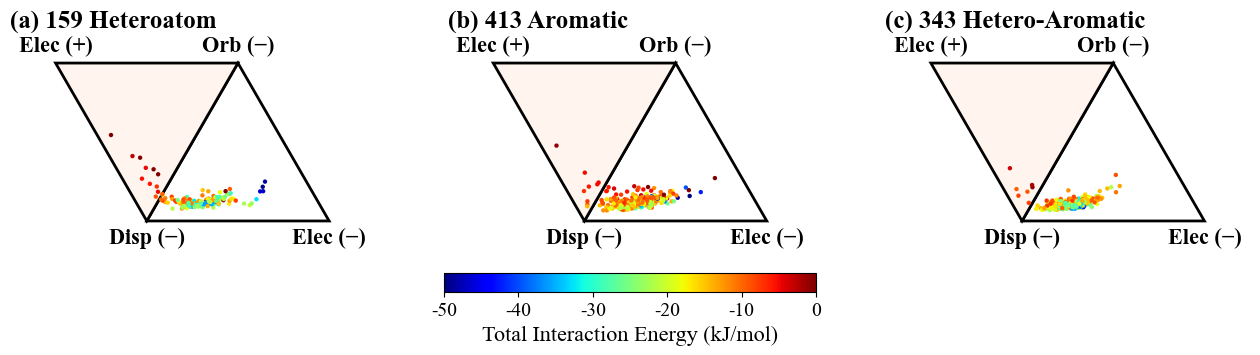

In [16]:
cmap_range = [-50, 0]
type = 'elec_orb_disp'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), df_whole[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), df_whole[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), df_whole[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

plt.savefig('ternary_hetratm-aromatic_2.png')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_44069/573937818.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


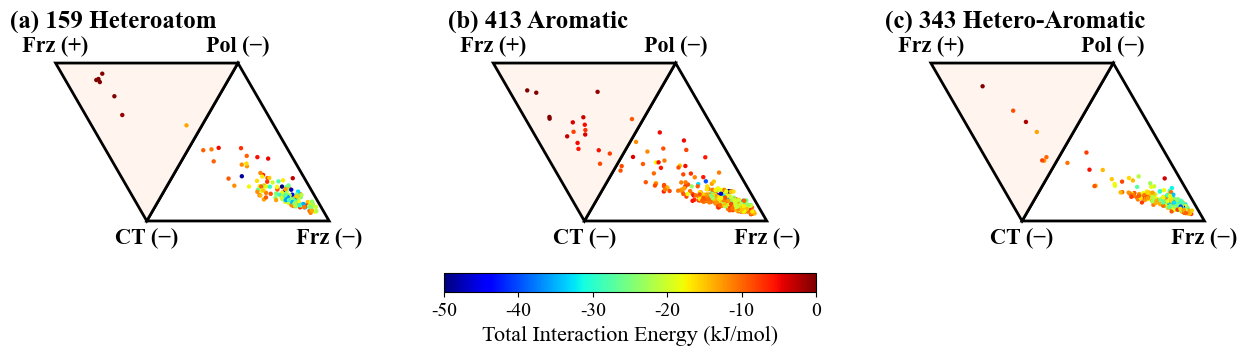

In [17]:
cmap_range = [-50, 0]
type = 'frz_pol_ct'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), df_whole[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), df_whole[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), df_whole[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

plt.savefig('ternary_hetratm-aromatic_3.png')

## Seperateing Parallel and T-Shaped

No difference

In [18]:
# cmap_range = [-50, 0]
# type = 'frz_orb_disp'

# fig, axes = plt.subplots(2, 3, figsize=(16, 10))
# sc = plot('ternary', (labels[0], 'a', type), df_P[0], axes[0, 0], cmap_range)
# plot('ternary', (labels[1], 'b', type), df_P[1], axes[0, 1], cmap_range)
# plot('ternary', (labels[2], 'c', type), df_P[2], axes[0, 2], cmap_range)
# plot('ternary', (labels[0], 'a', type), df_T[0], axes[1, 0], cmap_range)
# plot('ternary', (labels[1], 'b', type), df_T[1], axes[1, 1], cmap_range)
# plot('ternary', (labels[2], 'c', type), df_T[2], axes[1, 2], cmap_range)


# cbar = fig.colorbar(
#     sc, 
#     ax=axes, 
#     orientation='horizontal', 
#     shrink=0.3,
#     pad=0.05
# )
# cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
# cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

# plt.savefig('ternary_hetratm-aromatic_1.png')

# Heteroatom vs Pure Aromatic Bar Plot


## Bar Plot Ratio type formulation

### ratio1: $R_1 = \frac{\sum_{i} E_{i}^{(t)}}{\sum_{i} E_{i}^{(\text{total})}}$

### ratio2: $R_2 = \sum_{i} \frac{E_{i}^{(t)}}{E_{i}^{(\text{total})}}$

len: [159, 413, 343]
len: [492, 422]


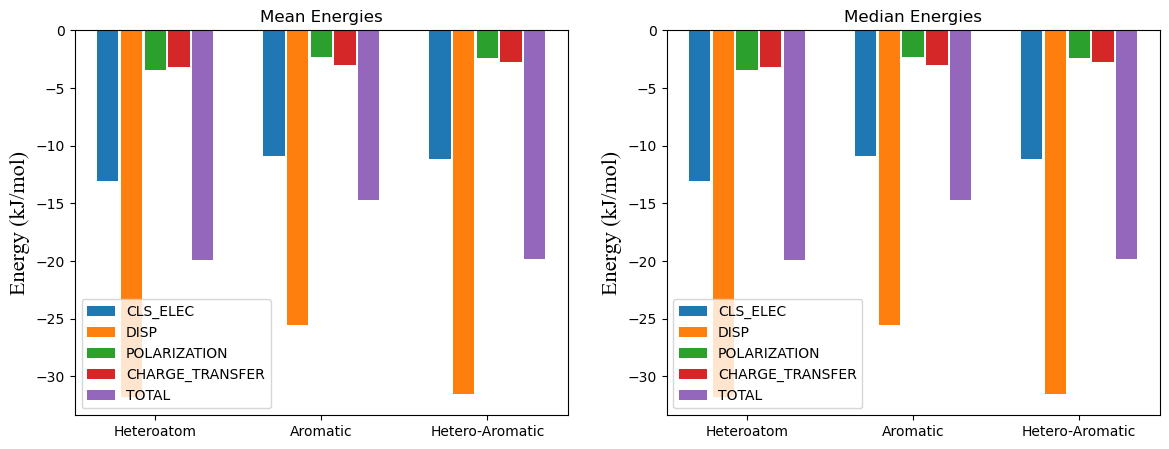

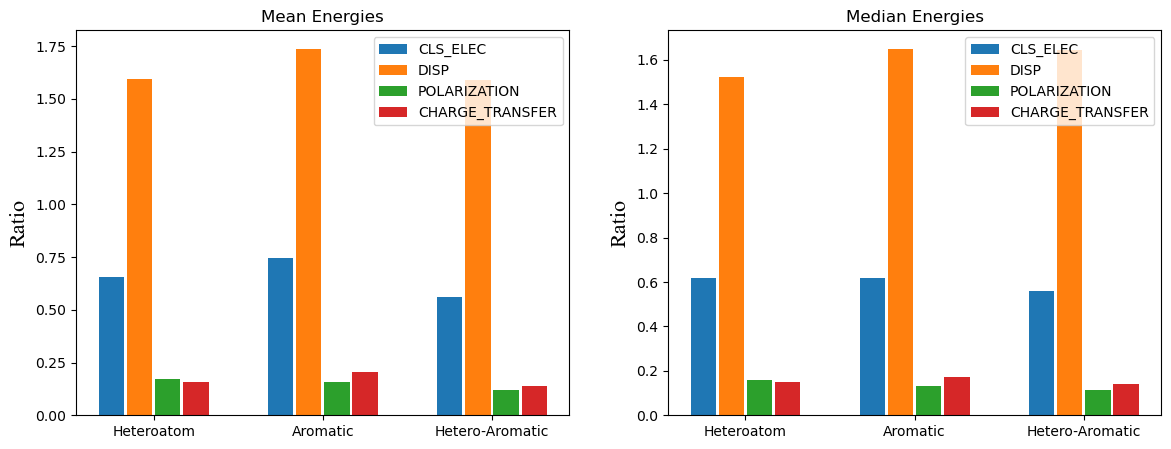

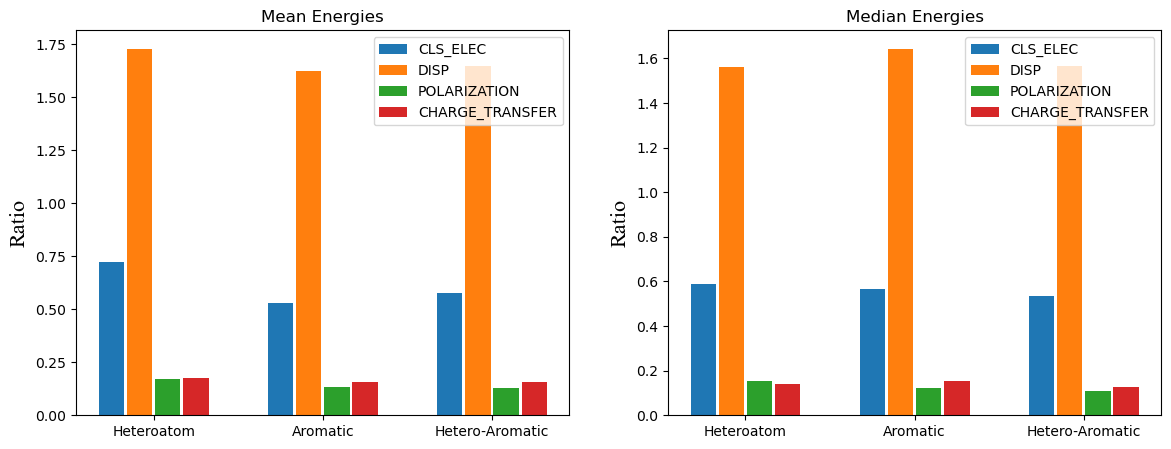

In [23]:
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: {list(map(len, df_whole))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_whole, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_whole, axes[1], median=False)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_all_hetratom-aromatic.png')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

print(f'len: {list(map(len, dfs))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_whole, axes[0], ratio1=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_whole, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic.png')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_whole, axes[0], ratio2=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_whole, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic.png')

## Parallel Heteroatom Aromatic Split

len: [99, 153, 236]


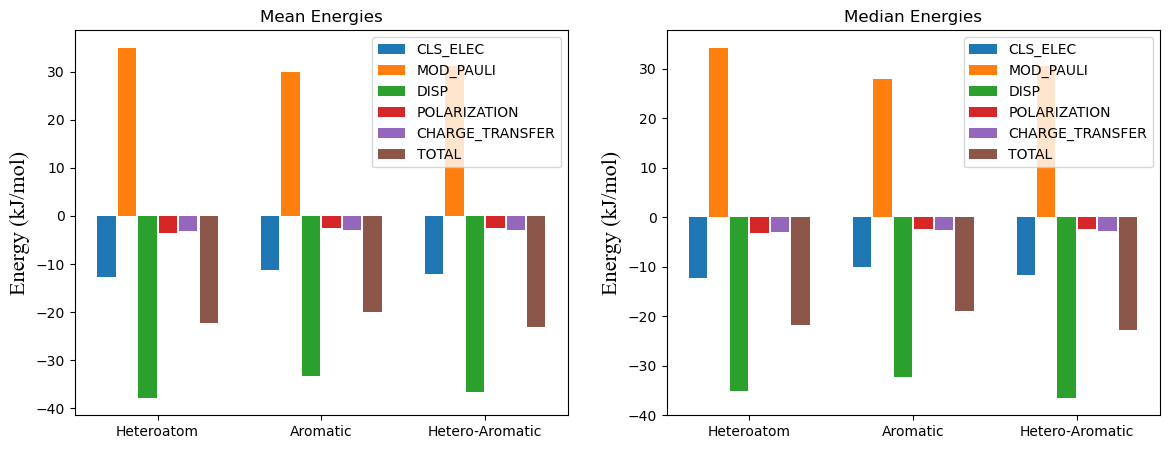

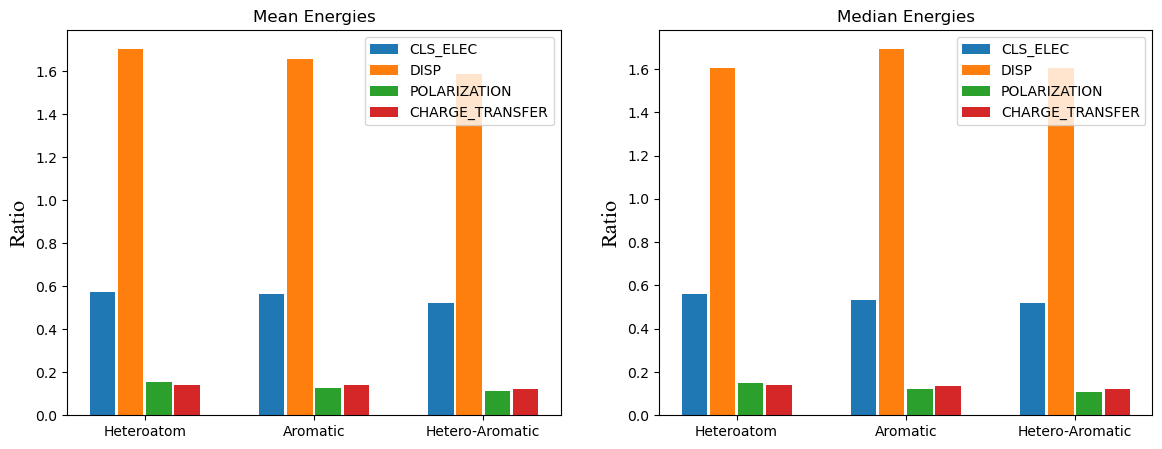

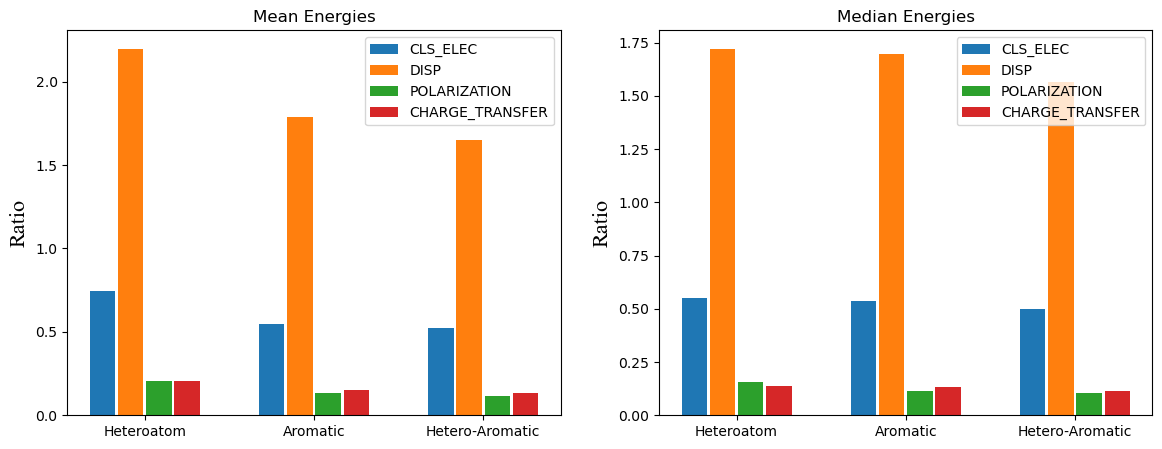

In [22]:
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: {list(map(len, df_P))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_P, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_P, axes[1], median=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic_P.png')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_P, axes[0], ratio1=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_P, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic_P.png')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_P, axes[0], ratio2=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_P, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic_P.png')

## T-Shaped Heteroatom Parallel split

len: [55, 256, 106]
len: [55, 256, 106]


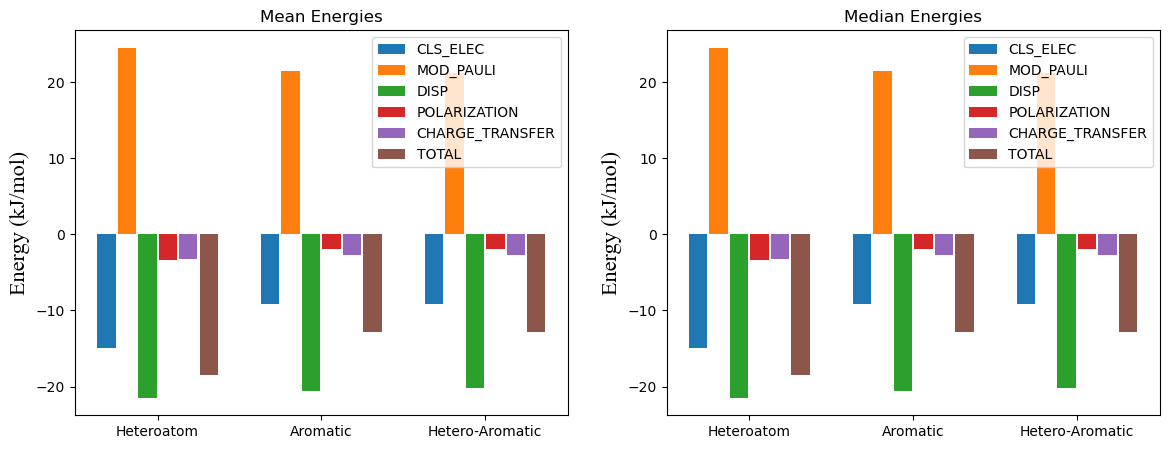

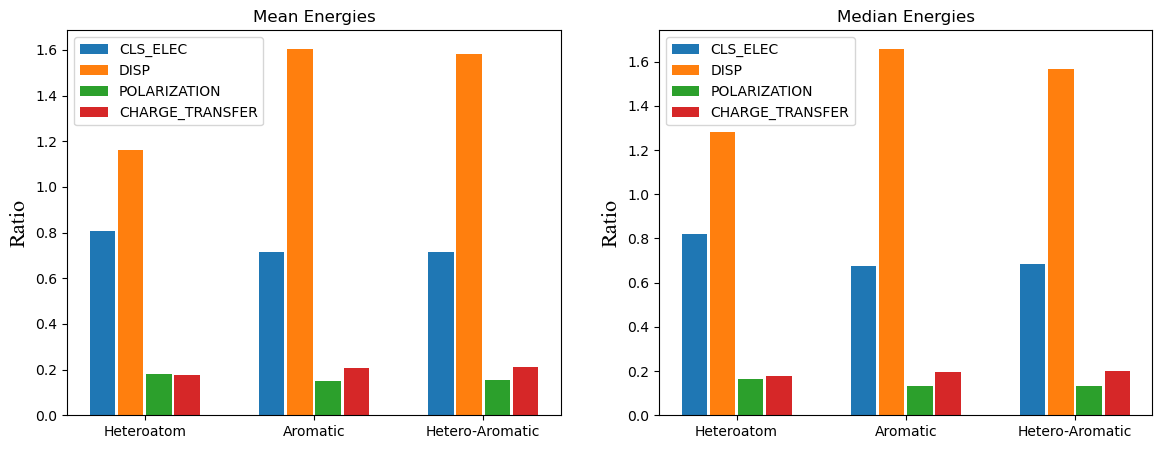

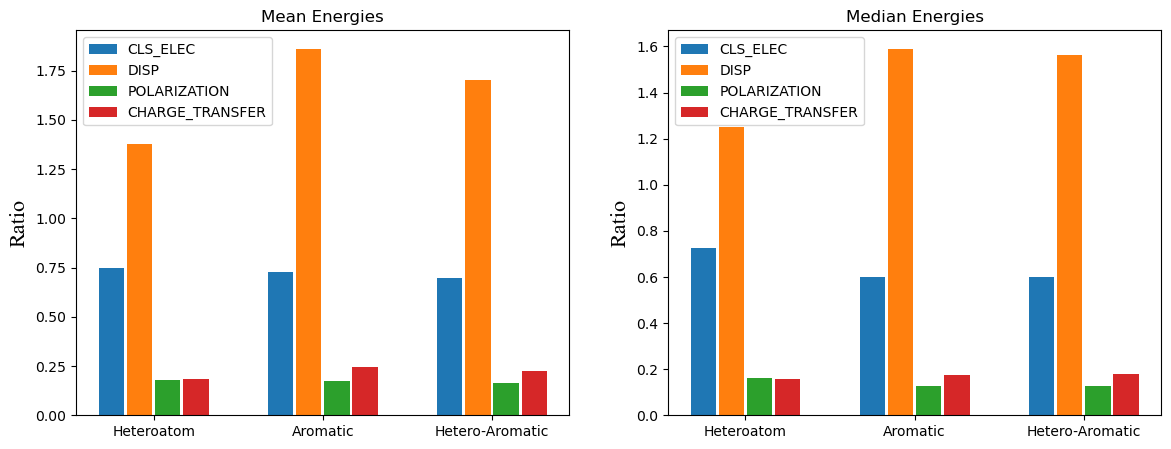

In [21]:
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: {list(map(len, df_T))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_T, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_T, axes[1], median=False)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_all_hetratom-aromatic_T.png')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

print(f'len: {list(map(len, df_T))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_T, axes[0], ratio1=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_T, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic_T.png')


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_T, axes[0], ratio2=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_T, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic_T.png')